# Встреча 4. Остановка: теория

> **Время:** 35 минут · **Дальше:** `practice.ipynb` · **Кейс:** «Горящие предложения», `../data/hotdeals_segmented.csv`

Продакт хочет смотреть результат теста каждый день и остановиться, как только «стало значимо». Обычный z-тест этого не разрешает: он рассчитан на один взгляд в конце. Разбираем, сколько стоит подглядывание и какие планы делают его честным.

Параметры кейса во всех расчётах: по 3 000 пользователей в группе в день, конверсия 4.8%, MDE +0.5 п.п., план — 14 дней. На каждую из двух основных метрик $\alpha = 2.5\%$ (двусторонний).

| Блок | Тезис | Минут |
| --- | --- | :---: |
| 1 | Каждый взгляд — новый шанс шуму пройти порог: при ежедневном просмотре ошибка ×4 | 8 |
| 2 | GST распределяет $\alpha$ по взглядам; O'Brien-Fleming почти не просит запаса выборки | 11 |
| 3 | mSPRT разрешает смотреть сколько угодно и продлевать; платим шириной и мощностью | 8 |
| 4 | Futility: останавливаем бесперспективный тест по условной мощности | 8 |

### Библиотеки и параметры

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import brentq

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = "#4C72B0", "#C44E52", "#55A868", "#7F7F7F", "#DD8452"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
norm = stats.norm

P_BASE, MDE, N_DAY, PLAN_DAYS = 0.048, 0.005, 3_000, 14
ALPHA_PRIMARY, POWER = 0.025, 0.80
N_MAX = N_DAY * PLAN_DAYS
SIGMA2_DIFF = P_BASE * (1 - P_BASE) + (P_BASE + MDE) * (1 - P_BASE - MDE)
THETA_MDE = MDE / np.sqrt(SIGMA2_DIFF / N_MAX)      # эффект MDE в единицах Z при Nmax
LOOKS = np.arange(1, PLAN_DAYS + 1) / PLAN_DAYS


def drift_paths(looks, drift: float, n_paths: int, seed: int = 1) -> np.ndarray:
    """Пути z-статистики Z(t) = (W(t) + drift·t) / sqrt(t) в долях данных looks."""
    looks = np.asarray(looks, dtype=float)
    rng = np.random.default_rng(seed)
    gaps = np.diff(looks, prepend=0.0)
    walk = rng.standard_normal((n_paths, len(looks)), dtype=np.float32) * np.sqrt(gaps) + drift * gaps
    return np.cumsum(walk, axis=1) / np.sqrt(looks)

## Блок 1. Цена подглядывания

**Тезис.** Обычный тест держит $\alpha$ только при одном взгляде. Каждый дополнительный взгляд — ещё один шанс шуму пересечь порог. При ежедневном просмотре двухнедельного теста ложных «успехов» в 4 раза больше заявленного.

Накопленная z-статистика при $H_0$ — случайное блуждание, нормированное на $\sqrt{t}$. Соседние дни сильно связаны: $\operatorname{corr}(Z_s, Z_t) = \sqrt{s/t}$. Поэтому ошибка растёт медленнее, чем при независимых проверках ($1 - 0.95^K$), но растёт без предела: при бесконечном просмотре любое блуждание рано или поздно пересечёт $\pm 1.96$.

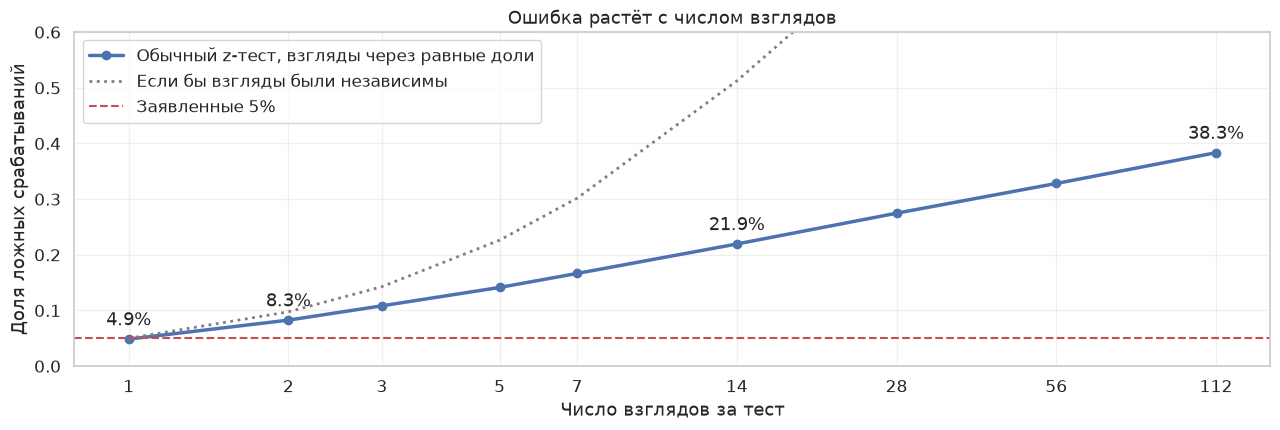

,1,2,3,5,7,14,28,56,112
FPR,0.049,0.083,0.108,0.141,0.166,0.219,0.275,0.328,0.383


In [2]:
looks_grid = np.array([1, 2, 3, 5, 7, 14, 28, 56, 112])
naive_fpr = [(np.abs(drift_paths(np.arange(1, k + 1) / k, 0.0, 100_000, seed=k)) > norm.ppf(0.975)).any(axis=1).mean()
             for k in looks_grid]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(looks_grid, naive_fpr, "-o", color=BLUE, linewidth=2.5, label="Обычный z-тест, взгляды через равные доли")
ax.plot(looks_grid, 1 - 0.95 ** looks_grid, ":", color=GRAY, linewidth=2, label="Если бы взгляды были независимы")
ax.axhline(0.05, color=RED, linestyle="--", linewidth=1.5, label="Заявленные 5%")
for k, v in zip(looks_grid, naive_fpr):
    if k in (1, 2, 14, 112):
        ax.annotate(f"{v:.1%}", (k, v), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set(xscale="log", xticks=looks_grid, xticklabels=looks_grid, ylim=(0, 0.6),
       xlabel="Число взглядов за тест", ylabel="Доля ложных срабатываний", title="Ошибка растёт с числом взглядов")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
pd.Series(naive_fpr, index=looks_grid, name="FPR").to_frame().T

* 2 взгляда — 8%, 14 ежедневных — 22%, 112 (каждые три часа) — 38%. Здесь $\alpha = 5\%$, как у обычного теста «на глаз». В нашем плане на метрику $\alpha = 2.5\%$, и при ежедневном взгляде ошибка к 14-му дню — 12% (блок 3).
* Независимые проверки дали бы 51% уже при 14 взглядах: зависимость спасает, но не до 5%.
* Бонферрони ($0.05/K$) держит ошибку, но считает проверки независимыми и поэтому избыточно строг: теряем мощность.

Хуже всего то, что ложный «успех» обычно ранний: в первые дни оценка самая шумная. Команда, остановившаяся на 3-й день, не узнает, что к 14-му дню p-value часто возвращается к большим значениям. Такой A/A-тест — в практике, задание 1.

## Блок 2. Group sequential test и $\alpha$-spending

**Тезис.** GST заранее делит бюджет $\alpha$ между взглядами. Функция расхода $\alpha(t)$ задаёт, сколько ошибки накоплено к доле данных $t$. Граница на взгляде $i$ подбирается так, чтобы потратить ровно прирост $\alpha(t_i) - \alpha(t_{i-1})$ с учётом зависимости взглядов.

Две классические функции (в форме Lan-DeMets: работают при любом расписании, даже если взгляд пропущен):

$$
\alpha_{\text{OBF}}(t) = 2\left(1 - \Phi\left(\frac{z_{1-\alpha/2}}{\sqrt{t}}\right)\right), \qquad
\alpha_{\text{Pocock}}(t) = \alpha \log\big(1 + (e - 1)t\big).
$$

O'Brien-Fleming почти ничего не тратит в начале и бережёт $\alpha$ на конец. Pocock тратит равномерно.

**Запас выборки.** Строгие ранние границы съедают немного мощности. Чтобы её вернуть, максимальную выборку увеличивают: $N_{\max} = R \cdot n_{\text{fixed}}$. Зато при реальном эффекте тест в среднем останавливается раньше.

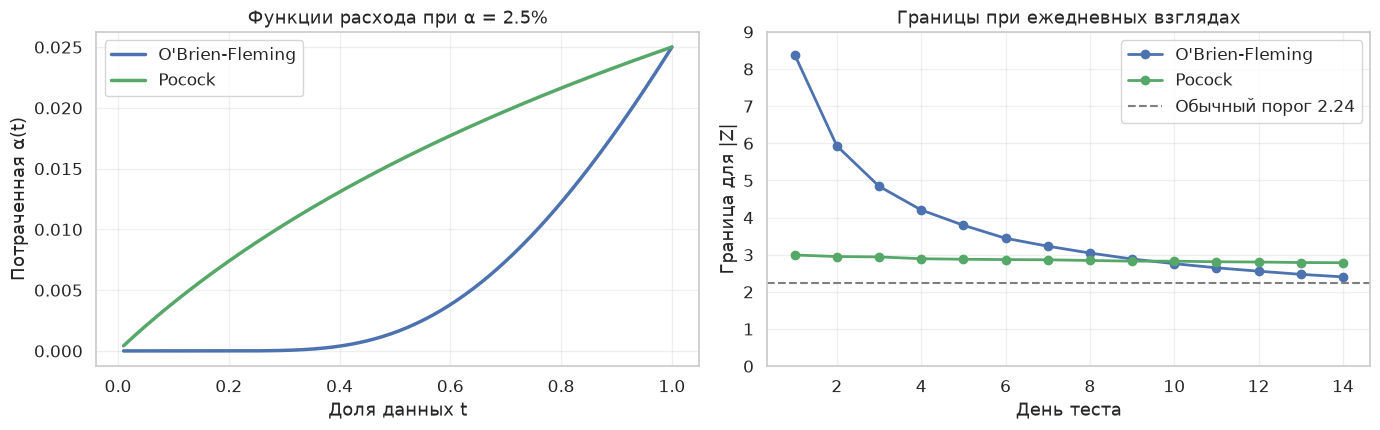

,Запас R,Дней до Nmax,Последняя граница,"E[n] при H0, % fixed","E[n] при MDE, % fixed"
Фиксированный тест,1.000,12.152,2.241,100.000,100.000
O'Brien-Fleming,1.052,12.781,2.402,104.694,79.407
Pocock,1.247,15.156,2.784,123.086,79.109


In [3]:
def obf_spending(t, alpha):
    return 2 * norm.sf(norm.ppf(1 - alpha / 2) / np.sqrt(t))


def pocock_spending(t, alpha):
    return alpha * np.log(1 + (np.e - 1) * t)


def gst_boundaries(spending, looks, alpha=ALPHA_PRIMARY, n_paths=600_000, seed=11) -> np.ndarray:
    """Границы для |Z|: на каждом взгляде тратим прирост функции расхода среди ещё не остановившихся путей."""
    z = np.abs(drift_paths(looks, 0.0, n_paths, seed))
    alive, spent, bounds = np.ones(n_paths, dtype=bool), 0.0, []
    for i, t in enumerate(looks):
        step = float(spending(t, alpha)) - spent
        spent += step
        k = int(step * n_paths)
        values = z[alive, i]
        bound = np.partition(values, -k)[-k] if k >= 100 else norm.isf(step / 2)
        bounds.append(bound)
        alive[alive] = values < bound
    return np.array(bounds)


def gst_power(bounds, drift, n_paths=200_000, seed=5) -> tuple:
    """Мощность и средняя доля выборки до остановки."""
    hits = np.abs(drift_paths(LOOKS, drift, n_paths, seed)) >= bounds
    fired = hits.any(axis=1)
    return fired.mean(), LOOKS[np.where(fired, hits.argmax(axis=1), len(LOOKS) - 1)].mean()


z_sum = norm.ppf(1 - ALPHA_PRIMARY / 2) + norm.ppf(POWER)
n_fixed = z_sum ** 2 * SIGMA2_DIFF / MDE ** 2
bounds = {"O'Brien-Fleming": gst_boundaries(obf_spending, LOOKS), "Pocock": gst_boundaries(pocock_spending, LOOKS)}
rows = {"Фиксированный тест": {"Запас R": 1.0, "Дней до Nmax": n_fixed / N_DAY, "Последняя граница": norm.ppf(1 - ALPHA_PRIMARY / 2),
                               "E[n] при H0, % fixed": 100.0, "E[n] при MDE, % fixed": 100.0}}
for name, b in bounds.items():
    r = brentq(lambda r: gst_power(b, z_sum * np.sqrt(r))[0] - POWER, 1.0, 1.6, xtol=1e-3)
    rows[name] = {"Запас R": r, "Дней до Nmax": r * n_fixed / N_DAY, "Последняя граница": b[-1],
                  "E[n] при H0, % fixed": 100 * r * gst_power(b, 0.0)[1],
                  "E[n] при MDE, % fixed": 100 * r * gst_power(b, z_sum * np.sqrt(r))[1]}

t_fine = np.linspace(0.01, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(t_fine, obf_spending(t_fine, ALPHA_PRIMARY), color=BLUE, linewidth=2.5, label="O'Brien-Fleming")
axes[0].plot(t_fine, pocock_spending(t_fine, ALPHA_PRIMARY), color=GREEN, linewidth=2.5, label="Pocock")
axes[0].set(xlabel="Доля данных t", ylabel="Потраченная α(t)", title="Функции расхода при α = 2.5%")
axes[0].legend()
days = np.arange(1, PLAN_DAYS + 1)
for (name, b), color in zip(bounds.items(), (BLUE, GREEN)):
    axes[1].plot(days, b, "-o", color=color, linewidth=2, label=name)
axes[1].axhline(norm.ppf(1 - ALPHA_PRIMARY / 2), color=GRAY, linestyle="--", label="Обычный порог 2.24")
axes[1].set(xlabel="День теста", ylabel="Граница для |Z|", ylim=(0, 9), title="Границы при ежедневных взглядах")
axes[1].legend()
plt.tight_layout()
plt.show()
pd.DataFrame(rows).T

* **O'Brien-Fleming:** граница 8.4 в первый день и 3.2 на конец первой недели — рано остановиться можно только при огромном эффекте. Последняя граница 2.40, почти обычный порог 2.24. Запас ~5%: 12.2 дня превращаются примерно в 12.7–12.8 (зависит от симуляции), после округления до недель — те же 14 дней.
* **Pocock:** границы ~2.8 почти на всех взглядах, запас ~25% — три недели вместо двух. Выигрывает по средней выборке только при эффектах заметно больше MDE.
* **Цена страховки при $H_0$:** если эффекта нет, GST тратит всю $N_{\max}$ — то есть больше фиксированного теста. Это решает futility (блок 4).

Практическое правило: **O'Brien-Fleming + $N_{\max}$ с запасом, округлённый до целых недель.** За $N_{\max}$ не выходим: весь бюджет $\alpha$ к этому моменту потрачен.

## Блок 3. mSPRT и always-valid inference

**Тезис.** mSPRT (mixture sequential probability ratio test) не требует ни расписания, ни $N_{\max}$: always-valid p-value и доверительная последовательность корректны в **любой** момент, сколько бы раз мы ни смотрели и как бы долго ни продлевали тест. Платим шириной интервала и мощностью.

Статистика — отношение правдоподобий, усреднённое по эффектам $\Delta \sim N(0, \tau^2)$. При нормальной оценке разности $\bar\Delta$ с дисперсией $V$:

$$
\Lambda_n = \sqrt{\frac{V}{V + \tau^2}}\exp\left(\frac{\bar\Delta^2 \tau^2}{2V(V + \tau^2)}\right), \qquad p_n = \min\left(p_{n-1}, \frac{1}{\Lambda_n}\right).
$$

$\Lambda_n$ при $H_0$ — мартингал со средним 1, поэтому по неравенству Вилля $P(\exists n: \Lambda_n \ge 1/\alpha) \le \alpha$. Отсюда «always valid».

**Выбор $\tau$.** Ширина последовательности минимальна там, где $\tau^2 \approx c \cdot V_{\text{план}}$, $c = -2\log\alpha + \log(1 - 2\log\alpha)$. При обычных $\alpha$ и мощности это почти ровно $\tau \approx$ MDE. $\tau$ фиксируется в плане, до запуска.

Сравним три правила при $H_0$, если тест по плану на 14 дней, а смотрят каждый день до 28-го (продлили «ещё на пару недель»).

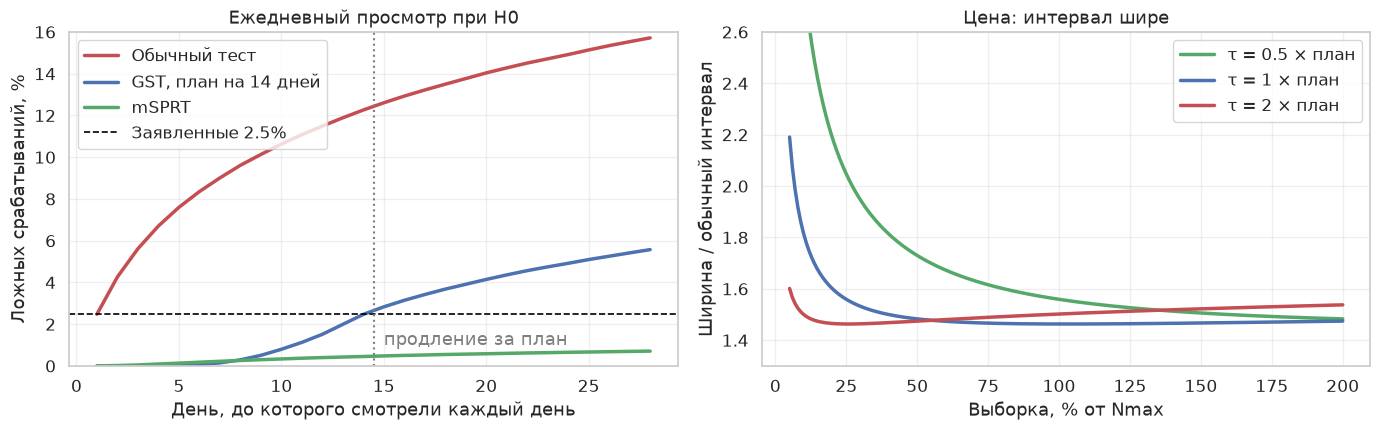

Минимум отношения ширины при τ по плану: 1.46 (на 103% Nmax)


,7,14,21,28
Обычный тест,0.090,0.123,0.143,0.157
"GST, план на 14 дней",0.001,0.025,0.044,0.056
mSPRT,0.002,0.004,0.006,0.007


In [4]:
def msprt_log_lambda(diff, V, tau):
    return 0.5 * np.log(V / (V + tau ** 2)) + diff ** 2 * tau ** 2 / (2 * V * (V + tau ** 2))


def msprt_radius(V, tau, alpha=ALPHA_PRIMARY):
    return np.sqrt(2 * V * (V + tau ** 2) / tau ** 2 * (np.log(1 / alpha) + 0.5 * np.log((V + tau ** 2) / V)))


c = -2 * np.log(ALPHA_PRIMARY) + np.log(1 - 2 * np.log(ALPHA_PRIMARY))
tau_unit = np.sqrt(c)                                     # τ в единицах sqrt(V_план), V_план = V при Nmax
days28 = np.arange(1, 29)
t28 = days28 / PLAN_DAYS
z = drift_paths(t28, 0.0, 300_000, seed=3)
b_obf = bounds["O'Brien-Fleming"]
naive = np.abs(z) >= norm.ppf(1 - ALPHA_PRIMARY / 2)
gst = np.abs(z) >= np.r_[b_obf, np.full(14, b_obf[-1])]   # после дня 14 повторяем последнюю границу
msprt = msprt_log_lambda(z / np.sqrt(t28), 1 / t28, tau_unit) >= np.log(1 / ALPHA_PRIMARY)
cumulative = pd.DataFrame({name: np.maximum.accumulate(hits, axis=1).mean(axis=0)
                           for name, hits in [("Обычный тест", naive), ("GST, план на 14 дней", gst), ("mSPRT", msprt)]},
                          index=days28)

share = np.linspace(0.05, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (name, color) in zip(cumulative.columns, (RED, BLUE, GREEN)):
    axes[0].plot(days28, 100 * cumulative[name], color=color, linewidth=2.5, label=name)
axes[0].axhline(100 * ALPHA_PRIMARY, color="black", linestyle="--", linewidth=1.2, label="Заявленные 2.5%")
axes[0].axvline(14.5, color=GRAY, linestyle=":", linewidth=1.5)
axes[0].text(15, 1, "продление за план", color=GRAY)
axes[0].set(xlabel="День, до которого смотрели каждый день", ylabel="Ложных срабатываний, %", ylim=(0, 16),
            title="Ежедневный просмотр при H0")
axes[0].legend(loc="upper left")
for ratio, color in [(0.5, GREEN), (1, BLUE), (2, RED)]:
    axes[1].plot(100 * share, msprt_radius(1 / share, ratio * tau_unit) / (norm.ppf(1 - ALPHA_PRIMARY / 2) / np.sqrt(share)),
                 color=color, linewidth=2.5, label=f"τ = {ratio} × план")
axes[1].set(xlabel="Выборка, % от Nmax", ylabel="Ширина / обычный интервал", ylim=(1.3, 2.6), title="Цена: интервал шире")
axes[1].legend()
plt.tight_layout()
plt.show()
width = msprt_radius(1 / share, tau_unit) / (norm.ppf(1 - ALPHA_PRIMARY / 2) / np.sqrt(share))
print(f"Минимум отношения ширины при τ по плану: {width.min():.2f} (на {100 * share[width.argmin()]:.0f}% Nmax)")
cumulative.loc[[7, 14, 21, 28]].T

* **Обычный тест** к 14-му дню ошибается в 12% случаев (при $\alpha = 2.5\%$), к 28-му — в 16%.
* **GST** держит 2.5% ровно до $N_{\max}$, а при продлении с последней границей ошибка снова растёт: 5.6% к 28-му дню.
* **mSPRT** не выходит за 2.5% никогда, сколько ни продлевай; при ежедневных взглядах он даже консервативен (0.4% к 14-му дню): гарантия рассчитана на непрерывный просмотр.
* **Цена:** интервал mSPRT в 1.46 раза шире обычного даже в лучшей точке, мощность за 14 дней — заметно ниже, чем у GST.

Где что применять:

| Ситуация | Метод |
| --- | --- |
| $N_{\max}$ известен, данные раз в день, продлевать не нужно | GST, O'Brien-Fleming с запасом |
| Длительность неизвестна, тест могут продлить | mSPRT, $\tau$ по плану |
| Нужно быстро ловить вред (guardrail, выкатка релиза) | mSPRT с первого дня |

**Важно.** Always-valid гарантия — про **постоянный** эффект. Если эффект меняется (новизна), последовательность накрывает средний эффект на уже пришедших пользователях, а не будущий.

## Блок 4. Futility: остановка за бесперспективностью

**Тезис.** Если к середине теста доказать эффект уже почти невозможно, оставшийся трафик лучше отдать следующей идее. Мерило — **условная мощность** (CP): вероятность к концу пройти финальную границу $b_K$ при текущих данных и предположении об эффекте.

На шкале $B(t) = \sqrt{t}\,Z_t$ путь — броуновское движение со сносом $\theta$ (эффект в единицах $Z$ при $N_{\max}$), и будущий прирост не зависит от прошлого: $B(1) - B(t) \sim N(\theta(1-t),\ 1-t)$. Отсюда

$$
\mathrm{CP}(\theta) = 1 - \Phi\left(\frac{b_K - \sqrt{t}\,z_t - \theta(1-t)}{\sqrt{1-t}}\right).
$$

Правило: $\mathrm{CP} < \gamma$ (обычно $\gamma = 0.1$–$0.2$) — останавливаемся. Главный выбор — какое $\theta$ подставить:

* **$\theta$ из плана** (MDE) — «есть ли шанс поймать то, ради чего затевали тест»;
* **текущий тренд** $\hat\theta = z_t/\sqrt{t}$ — «будущее как настоящее»; ранняя оценка шумная, правило агрессивное;
* $\theta = 0$ — почти никогда не останавливает.

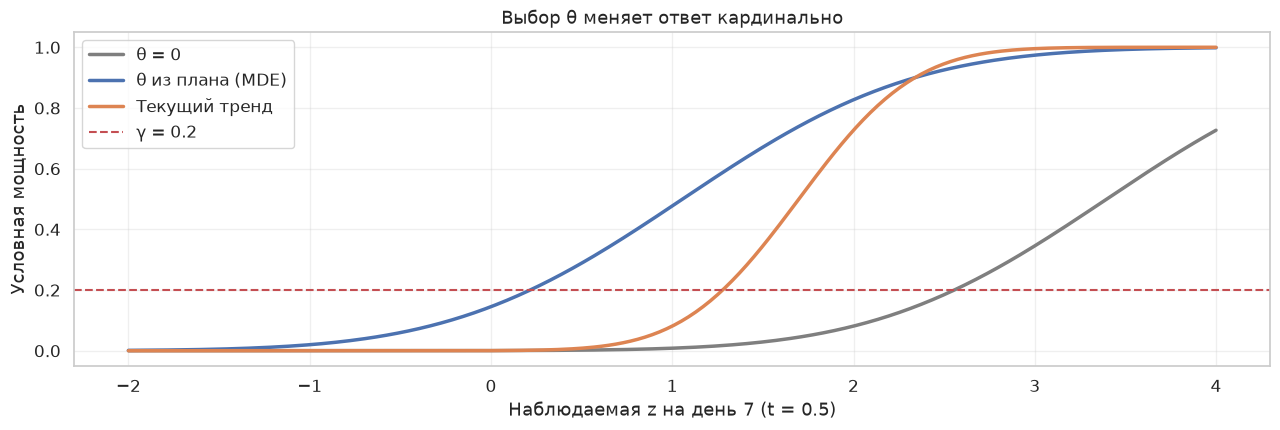

,"Выборка при H0, % Nmax","Выборка при MDE, % Nmax",Мощность при MDE
Без futility,99.539,73.189,0.838
"CP по плану < 0.2, дни 7 и 10",61.918,71.152,0.831
"CP по тренду < 0.2, дни 7 и 10",53.016,65.491,0.766


In [5]:
def conditional_power(z_t, t, theta, final_bound):
    return norm.sf((final_bound - np.sqrt(t) * z_t - theta * (1 - t)) / np.sqrt(1 - t))


b_final = b_obf[-1]
z_grid = np.linspace(-2, 4, 300)
t_half = 0.5


def futility_oc(drift, mode, gamma=0.2, fut_days=(7, 10), n_paths=200_000, seed=5) -> tuple:
    """Мощность и средняя доля выборки GST O'Brien-Fleming с futility на днях fut_days."""
    z = drift_paths(LOOKS, drift, n_paths, seed)
    alive, win, stop = np.ones(n_paths, dtype=bool), np.zeros(n_paths, dtype=bool), np.ones(n_paths)
    for i, t in enumerate(LOOKS):
        crossed = alive & (np.abs(z[:, i]) >= b_obf[i])
        win |= crossed & (z[:, i] > 0)
        stop[crossed] = t
        alive &= ~crossed
        if mode and i + 1 in fut_days:
            theta = THETA_MDE if mode == "plan" else z[:, i] / np.sqrt(t)
            cut = alive & (conditional_power(z[:, i], t, theta, b_final) < gamma)
            stop[cut] = t
            alive &= ~cut
    return win.mean(), 100 * stop.mean()


rows = {}
for name, mode in [("Без futility", None), ("CP по плану < 0.2, дни 7 и 10", "plan"), ("CP по тренду < 0.2, дни 7 и 10", "trend")]:
    (_, n_h0), (power, n_h1) = futility_oc(0.0, mode), futility_oc(THETA_MDE, mode)
    rows[name] = {"Выборка при H0, % Nmax": n_h0, "Выборка при MDE, % Nmax": n_h1, "Мощность при MDE": power}

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(z_grid, conditional_power(z_grid, t_half, 0.0, b_final), color=GRAY, linewidth=2.5, label="θ = 0")
ax.plot(z_grid, conditional_power(z_grid, t_half, THETA_MDE, b_final), color=BLUE, linewidth=2.5, label="θ из плана (MDE)")
ax.plot(z_grid, conditional_power(z_grid, t_half, z_grid / np.sqrt(t_half), b_final), color=ORANGE, linewidth=2.5, label="Текущий тренд")
ax.axhline(0.2, color=RED, linestyle="--", linewidth=1.5, label="γ = 0.2")
ax.set(xlabel="Наблюдаемая z на день 7 (t = 0.5)", ylabel="Условная мощность", title="Выбор θ меняет ответ кардинально")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
pd.DataFrame(rows).T

* При $z_7 = 0$ CP по плану ≈ 0.15, по тренду ≈ 0: тренд «хоронит» тест, который ещё мог вырасти до MDE.
* **Futility по плану** сокращает среднюю выборку при $H_0$ примерно с 100% до ~62% $N_{\max}$ и теряет меньше 1 п.п. мощности. **По тренду** экономит больше, но теряет ~7 п.п. мощности.
* Ложных запусков futility не добавляет: она только убирает пути, которые и так вряд ли дошли бы до границы.

**Binding или non-binding.**

* **Non-binding:** границы эффективности считаем так, будто futility нет. Стоп — рекомендация: отменить можно, $\alpha$ не вырастет.
* **Binding:** границы считаем на путях, переживших futility, — они чуть ниже, тест чуть мощнее. Но стоп обязателен: проигнорировали — $\alpha$ превышена.

В продукте стоп за бесперспективность часто отменяют («давайте ещё посмотрим»), поэтому почти всегда выбирают **non-binding**.

## Итоги

* Ежедневный взгляд в обычный тест — ~22% ложных срабатываний вместо 5% (при $\alpha = 2.5\%$ — 12% вместо 2.5%).
* GST делит $\alpha$ функцией расхода; O'Brien-Fleming просит ~5% запаса выборки, Pocock — ~25%. За $N_{\max}$ не выходим.
* mSPRT корректен при любом числе взглядов и продлении; $\tau$ — из плана ($\approx$ MDE). Платим шириной (×1.46) и мощностью. Его место — guardrail и тесты с неизвестной длительностью.
* Futility по условной мощности с $\theta$ из плана экономит ~40% выборки при нулевом эффекте; делаем non-binding.
* Честная остановка контролирует ошибку **решения**, но не точность оценки: рано остановленный тест завышает эффект. Это и правила отчёта — на практике.